# 02 — Ön işleme ve baseline (Logistic Regression)

**Amaç:** Eğitim ve canlı tahminin ortak kullanacağı ön işleme pipeline'ını kurmak ve basit bir
baseline ile "aşılması gereken çıtayı" belirlemek.

Bu notebook'ta **test setine dokunulmaz**; tüm kararlar eğitim (CV) ve doğrulama seti üzerinden verilir.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from loan_ml.data import DEFAULT_FLAG, FEATURES, RANDOM_STATE, SENSITIVE, TARGET, clean, load_raw, split, xy
from loan_ml.evaluation import best_f1_threshold, evaluate, metrics_row
from loan_ml.features import build_pipeline, build_tree_preprocessor

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 110

## 1. Veri, temizlik ve bölme

In [2]:
data = clean(load_raw())
splits = split(data)

summary = pd.DataFrame({
    name: {
        "satır": len(part),
        "onay oranı": part[TARGET].mean(),
        "`No` alt grubu satır": int((part[DEFAULT_FLAG] == "No").sum()),
        "`No` alt grubu onay oranı": part.loc[part[DEFAULT_FLAG] == "No", TARGET].mean(),
    }
    for name, part in [("eğitim", splits.train), ("doğrulama", splits.val), ("test", splits.test)]
}).T
summary

,satır,onay oranı,`No` alt grubu satır,`No` alt grubu onay oranı
eğitim,"31,493.0000",0.2223,"15,498.0000",0.4517
doğrulama,"6,748.0000",0.2223,"3,306.0000",0.4537
test,"6,749.0000",0.2223,"3,331.0000",0.4503


In [3]:
assert SENSITIVE not in FEATURES, "person_gender model girdisi olamaz"
print(f"Model girdileri ({len(FEATURES)}):")
for f in FEATURES:
    print("  -", f)

Model girdileri (12):
  - person_age
  - person_income
  - person_emp_exp
  - loan_amnt
  - loan_int_rate
  - loan_percent_income
  - cb_person_cred_hist_length
  - credit_score
  - person_education
  - person_home_ownership
  - loan_intent
  - previous_loan_defaults_on_file


## 2. Ön işleme pipeline'ı

| Kolon(lar) | Dönüşüm |
|---|---|
| 8 sayısal kolon | Ağaç modelleri: olduğu gibi · Doğrusal model: gelirde `log1p`, ardından `StandardScaler` |
| `person_education` | `OrdinalEncoder` (High School < Associate < Bachelor < Master < Doctorate) |
| `person_home_ownership`, `loan_intent` | `OneHotEncoder(handle_unknown="ignore")` |
| `previous_loan_defaults_on_file` | No → 0, Yes → 1 |

Tüm adımlar modelle birlikte tek bir `Pipeline` nesnesindedir; canlıda aynı nesne kullanılacaktır.

In [4]:
X_train, y_train = xy(splits.train)
X_val, y_val = xy(splits.val)

tree_pre = build_tree_preprocessor().fit(X_train)
encoded = pd.DataFrame(tree_pre.transform(X_train.head(3)), columns=tree_pre.get_feature_names_out())
print("Kodlanmış kolon sayısı:", encoded.shape[1])
encoded.T

Kodlanmış kolon sayısı: 20


,0,1,2
person_age,23.0000,28.0000,29.0000
person_income,"76,732.0000","60,918.0000","101,870.0000"
person_emp_exp,2.0000,5.0000,5.0000
loan_amnt,"18,000.0000","12,000.0000","13,000.0000"
loan_int_rate,10.9900,13.1100,12.5300
loan_percent_income,0.2300,0.2000,0.1300
cb_person_cred_hist_length,3.0000,10.0000,7.0000
credit_score,618.0000,564.0000,600.0000
person_education,1.0000,1.0000,3.0000
person_home_ownership_MORTGAGE,0.0000,0.0000,0.0000


## 3. Logistic Regression — hiperparametre araması

5 katlı katmanlı CV, hedef metrik ROC-AUC. `C` (düzenlileştirme) ve `class_weight` aranır.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=2000), linear=True),
    param_grid={"model__C": [0.01, 0.1, 1.0, 10.0], "model__class_weight": [None, "balanced"]},
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_brier": "neg_brier_score"},
    refit="roc_auc",
    cv=cv,
    n_jobs=1,
)
search.fit(X_train, y_train)

cv_table = pd.DataFrame(search.cv_results_)[
    ["param_model__C", "param_model__class_weight", "mean_test_roc_auc", "std_test_roc_auc",
     "mean_test_pr_auc", "mean_test_neg_brier"]
].rename(columns={
    "param_model__C": "C", "param_model__class_weight": "class_weight",
    "mean_test_roc_auc": "CV ROC-AUC", "std_test_roc_auc": "std",
    "mean_test_pr_auc": "CV PR-AUC", "mean_test_neg_brier": "CV −Brier",
}).sort_values("CV ROC-AUC", ascending=False)
cv_table

,C,class_weight,CV ROC-AUC,std,CV PR-AUC,CV −Brier
6,10.0000,NaN,0.9556,0.0024,0.8607,-0.0709
4,1.0000,NaN,0.9556,0.0024,0.8607,-0.0709
2,0.1000,NaN,0.9555,0.0024,0.8608,-0.0709
7,10.0000,balanced,0.9555,0.0024,0.8594,-0.0929
5,1.0000,balanced,0.9555,0.0024,0.8594,-0.0929
3,0.1000,balanced,0.9555,0.0024,0.8595,-0.0928
1,0.0100,balanced,0.9553,0.0025,0.8602,-0.0926
0,0.0100,NaN,0.9550,0.0024,0.8610,-0.0712


`class_weight="balanced"` sıralama metriklerini (ROC-AUC, PR-AUC) neredeyse hiç değiştirmez, ancak
olasılıkları yukarı kaydırdığı için Brier skorunu (kalibrasyonu) bozar. Arayüzde olasılık
gösterileceğinden, baseline için **ağırlıksız** ve en iyi CV ROC-AUC'ye sahip `C` seçilir.

In [6]:
unweighted = cv_table[cv_table["class_weight"].isna()]
best_c = float(unweighted.iloc[0]["C"])
print("Seçilen C:", best_c)

baseline = build_pipeline(LogisticRegression(C=best_c, max_iter=2000), linear=True).fit(X_train, y_train)
val_proba = baseline.predict_proba(X_val)[:, 1]

Seçilen C: 10.0


## 4. Doğrulama seti sonuçları

Karar eşiği 0,5 varsayılmaz; doğrulama setinde F1'i en yükselten eşik seçilir.

In [7]:
threshold = best_f1_threshold(y_val, val_proba)
result = evaluate(splits.val, val_proba, threshold)
print(f"F1'i en yükselten eşik: {threshold:.3f}")

table = pd.DataFrame({
    "genel": {k: v for k, v in result["overall"].items() if k != "confusion_matrix"},
    "`No` alt grubu": {k: v for k, v in result["no_default"].items() if k != "confusion_matrix"},
})
table

F1'i en yükselten eşik: 0.450


,genel,`No` alt grubu
n,"6,748.0000","3,306.0000"
positive_rate,0.2223,0.4537
roc_auc,0.9547,0.8683
pr_auc,0.8566,0.8566
f1,0.7733,0.7733
precision,0.7561,0.7561
recall,0.7913,0.7913
brier,0.0713,0.1456


Genel ROC-AUC, geçmiş temerrüt kaydı olan (tamamı ret) kolay yarı nedeniyle yüksektir. Modelin gerçek
ayırt etme gücünü **`No` alt grubu** sütunu gösterir; XGBoost'un geçmesi gereken çıta budur.

PR-AUC, F1, precision ve recall iki sütunda aynıdır: tüm onaylar `No` alt grubundadır ve model
geçmiş temerrüt kaydı olan hiçbir başvuruyu onaylamaz, dolayısıyla pozitif sınıfa ilişkin sayımlar
değişmez. Fark yaratan metrikler ROC-AUC ve Brier'dır.

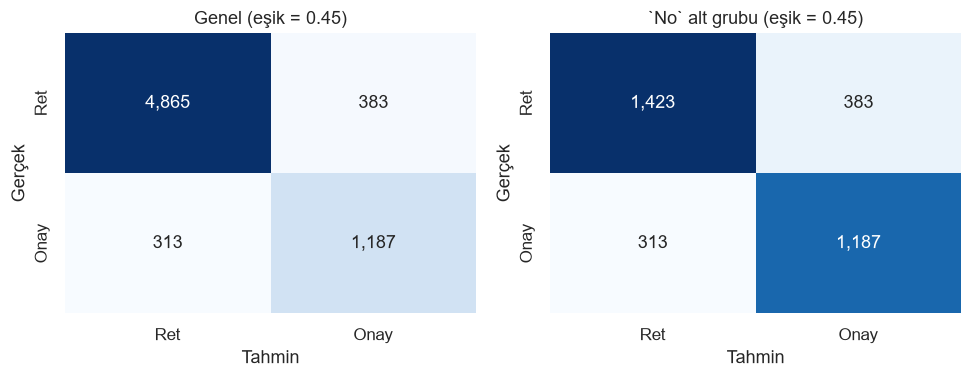

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (title, key) in zip(axes, [("Genel", "overall"), ("`No` alt grubu", "no_default")]):
    cm = result[key]["confusion_matrix"]
    matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Ret", "Onay"], yticklabels=["Ret", "Onay"])
    ax.set(title=f"{title} (eşik = {threshold:.2f})", xlabel="Tahmin", ylabel="Gerçek")
plt.tight_layout()
plt.show()

## 5. Kalibrasyon

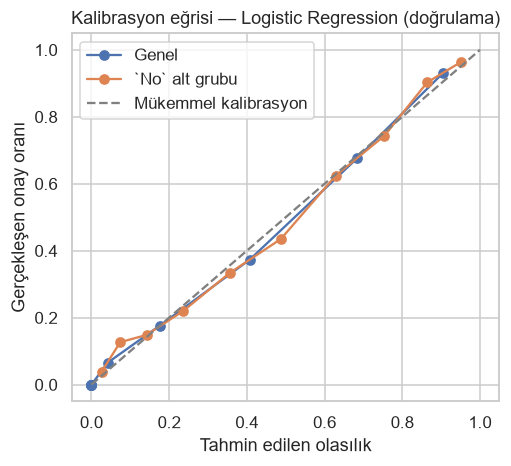

In [9]:
no_default_val = (splits.val[DEFAULT_FLAG] == "No").to_numpy()
fig, ax = plt.subplots(figsize=(4.8, 4.4))
for label, mask in [("Genel", np.ones(len(y_val), dtype=bool)), ("`No` alt grubu", no_default_val)]:
    frac, mean_pred = calibration_curve(y_val[mask], val_proba[mask], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=label)
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Mükemmel kalibrasyon")
ax.set(title="Kalibrasyon eğrisi — Logistic Regression (doğrulama)",
       xlabel="Tahmin edilen olasılık", ylabel="Gerçekleşen onay oranı")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Katsayılar

Özellikler standartlaştırıldığı için katsayılar karşılaştırılabilir. Pozitif katsayı onay
olasılığını artırır.

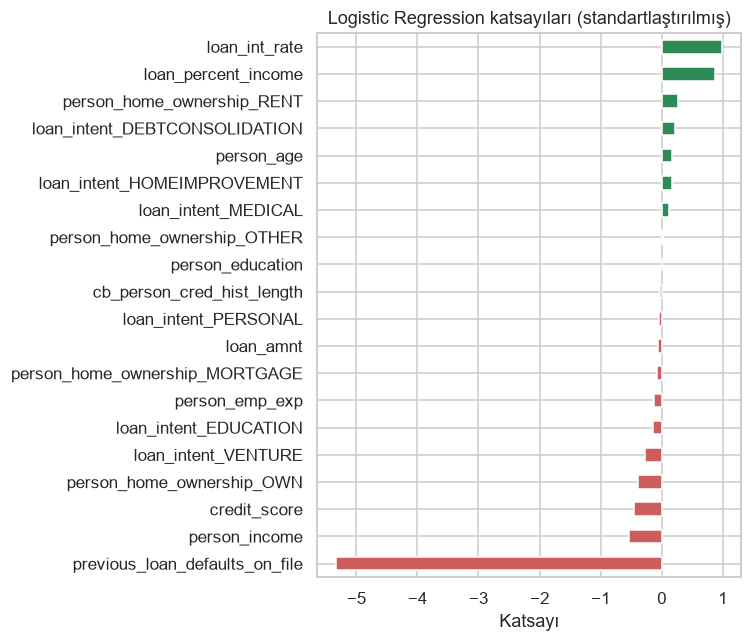

In [10]:
names = baseline.named_steps["preprocess"].named_steps["encode"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["model"].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "seagreen", "indianred"))
ax.set(title="Logistic Regression katsayıları (standartlaştırılmış)", xlabel="Katsayı")
plt.tight_layout()
plt.show()

Katsayıların yönü EDA'daki bulguyu doğrular: geçmiş temerrüt kaydı açık ara en güçlü (negatif)
etkendir; kredi/gelir oranı ve faiz oranı arttıkça "onay" olasılığı **artar**, gelir arttıkça
**azalır**. Bu, etiketin yönüne ilişkin açık konuyla aynıdır (bkz. `01_eda.ipynb`, Bölüm 7).

## 7. Baseline özeti

In [11]:
pd.DataFrame([metrics_row("Logistic Regression (baseline)", result)]).set_index("model").T

model,Logistic Regression (baseline)
overall_roc_auc,0.9547
overall_pr_auc,0.8566
overall_f1,0.7733
overall_precision,0.7561
overall_recall,0.7913
overall_brier,0.0713
no_default_roc_auc,0.8683
no_default_pr_auc,0.8566
no_default_f1,0.7733
no_default_precision,0.7561
